# ML Classification Model Variants

This notebook compares scikit-learn, PyTorch, and TensorFlow classifiers on a derived compatibility label. It automatically picks the first binary label with both classes present.

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display

from src.ml_model_utils import (
    classification_target,
    model_runs_frame,
    reduce_feature_set,
    run_sklearn_classification_models,
    run_tensorflow_classifier,
)
from src.utils import fs_utils
from src.vulkan_math_data import feature_matrix, load_ml_dataset

project_root, data_dir = fs_utils.get_data_dir()
project_root, data_dir

2026-06-04 11:40:52.719790: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-04 11:40:53.651586: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-04 11:40:54.176240: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-04 11:40:54.180249: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-04 11:40:54.818637: I tensorflow/core/platform/cpu_feature_gua

(PosixPath('/opt/pc-hardware-analysis'),
 PosixPath('/opt/pc-hardware-analysis/data'))

In [5]:
ml_frame, diagnostics = load_ml_dataset()
X, _ = feature_matrix(ml_frame)
X = reduce_feature_set(X, max_features=16)
y, target_name = classification_target(ml_frame)
print("Classification target used:", target_name)
print("Class counts:", y.value_counts().to_dict())
display(
    ml_frame[
        [
            "report_id",
            "normalized_gpu_name",
            "label__raytracing_capable",
            "label__advanced_rendering_capable",
            "label__high_capability",
        ]
    ]
)

Classification target used: label__high_capability
Class counts: {1: 277, 0: 270}


,report_id,normalized_gpu_name,label__raytracing_capable,label__advanced_rendering_capable,label__high_capability
0,10934,rtx 3090,1,0,0
1,10993,rtx 3080,1,0,0
2,10993,rtx 3080,1,0,0
3,11121,rtx 3080,1,0,0
4,11121,rtx 3080,1,0,0
...,...,...,...,...,...
542,49144,arc a770,1,0,0
543,49180,rtx 4080,1,1,1
544,49180,rtx 4080,1,1,1
545,49185,rtx 5090,1,1,1


In [ ]:
if y.nunique() < 2:
    print(
        "Classification models skipped because the selected target has only one class."
    )
    all_runs = []
else:
    sklearn_runs = run_sklearn_classification_models(X, y)
    tensorflow_run = run_tensorflow_classifier(X, y, epochs=50)
    all_runs = sklearn_runs + tensorflow_run
    display(model_runs_frame(all_runs))

,framework,model,accuracy
0,scikit-learn,logistic_regression,0.95064
1,scikit-learn,random_forest_classifier,0.95064
2,scikit-learn,gradient_boosting_classifier,0.95064
3,PyTorch,dense_classifier,0.95064
4,TensorFlow,keras_dense_classifier,0.95064


,report_id,normalized_gpu_name,target,scikit-learn::logistic_regression,scikit-learn::random_forest_classifier,scikit-learn::gradient_boosting_classifier,PyTorch::dense_classifier,TensorFlow::keras_dense_classifier
0,10934,rtx 3090,0,0,0,0,0,0
1,10993,rtx 3080,0,0,0,0,0,0
2,10993,rtx 3080,0,0,0,0,0,0
3,11121,rtx 3080,0,0,0,0,0,0
4,11121,rtx 3080,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...
542,49144,arc a770,0,0,0,0,0,0
543,49180,rtx 4080,1,1,1,1,1,1
544,49180,rtx 4080,1,1,1,1,1,1
545,49185,rtx 5090,1,1,1,1,1,1


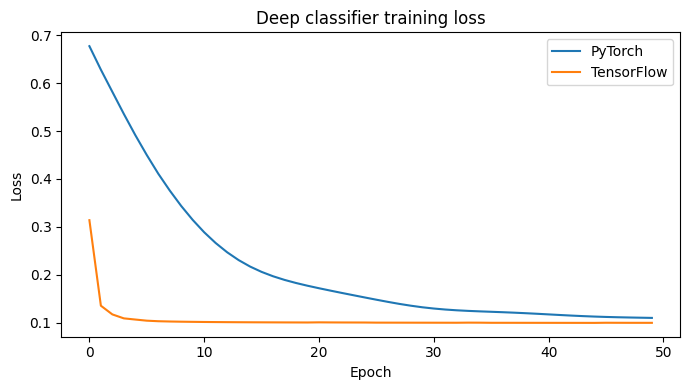

In [ ]:
if all_runs:
    prediction_frame = ml_frame[["report_id", "normalized_gpu_name"]].copy()
    prediction_frame["target"] = y.to_numpy()
    for run in all_runs:
        prediction_frame[f"{run.framework}::{run.name}"] = run.predictions
    display(prediction_frame)

    plt.figure(figsize=(7, 4))
    plt.plot(tensorflow_run.details["loss_history"], label="TensorFlow")
    plt.title("Deep classifier training loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()